In [2]:
import numpy as np
import re 
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd

In [29]:
def data_from_filename(folder):
    rows = []

    for file in os.listdir(folder): # Listar archivos

        m = re.search(r"_L(\d+)_T([0-9.]+)_N\d+_([0-1])", file) # Extraer parametros
        if not m:
            continue

        L, T, class_ = m.groups()
        rows.append({
            'file': file,
            'L': int(L),
            'T': float(T),
            'class': int(class_)
        })

    return pd.DataFrame(rows, columns=['file', 'L', 'T', 'class'])

files = data_from_filename('./../data/')

In [53]:
file = './../data/ising_L10_T3.900_N1000_1.txt'

with open(file, 'r') as f:
    lines = f.readlines()

metadata = lines[0] #Todo: Convertir metadata a key - value
spins = lines[1:]

spins[0][::-2]
array = np.array(spins[0][:-1].split(',')).astype(int).reshape(10, 10)

array

array([[-1, -1, -1, -1, -1, -1, -1, -1,  1, -1],
       [-1, -1,  1,  1, -1, -1, -1, -1, -1, -1],
       [ 1, -1,  1, -1,  1, -1,  1, -1, -1, -1],
       [-1, -1,  1, -1, -1,  1, -1, -1, -1, -1],
       [ 1, -1, -1, -1, -1, -1, -1, -1, -1,  1],
       [ 1,  1, -1, -1, -1,  1, -1,  1, -1,  1],
       [-1,  1,  1,  1, -1,  1,  1,  1, -1, -1],
       [ 1, -1, -1, -1, -1,  1, -1, -1, -1,  1],
       [ 1, -1, -1, -1, -1,  1, -1, -1, -1, -1],
       [ 1, -1, -1, -1, -1, -1, -1, -1,  1,  1]])

In [59]:
def read_file(file, L, function):
    with open(file, 'r') as f:
        lines = f.readlines()

    metadata = lines[0] #Todo: Convertir metadata a key - value
    spins = lines[1:] # Leer configuraciones de espines

    distribution = []
    for spin in spins:
        array = np.array(spin[:-1].split(',')).astype(int).reshape(L, L)
        distribution.append(function(array))

    return distribution



# Energía

In [ ]:
# Condiciones de frontera periódicas
def pbc(i, L):
    """Condiciones de frontera periódicas."""
    if i >= L:
        return i % L
    elif i < 0:
        return (i % L + L) % L
    else:
        return i


# Cálculo de la energía total del sistema
def energy(spin, J=1, H=0):

    L = spin.shape[0]
    
    # Término de interacción entre primeros vecinos
    # Sumamos interacciones hacia la derecha y hacia abajo para evitar doble conteo
    interaction_energy = 0.0
    
    # Interacciones horizontales (hacia la derecha)
    interaction_energy -= J * np.sum(spin[:, :-1] * spin[:, 1:])
    interaction_energy -= J * np.sum(spin[:, -1] * spin[:, 0])  # Condición periódica
    
    # Interacciones verticales (hacia abajo)
    interaction_energy -= J * np.sum(spin[:-1, :] * spin[1:, :])
    interaction_energy -= J * np.sum(spin[-1, :] * spin[0, :])  # Condición periódica
    
    # Término del campo magnético externo
    field_energy = -H * np.sum(spin)
    
    return interaction_energy + field_energy


<Axes: ylabel='Count'>

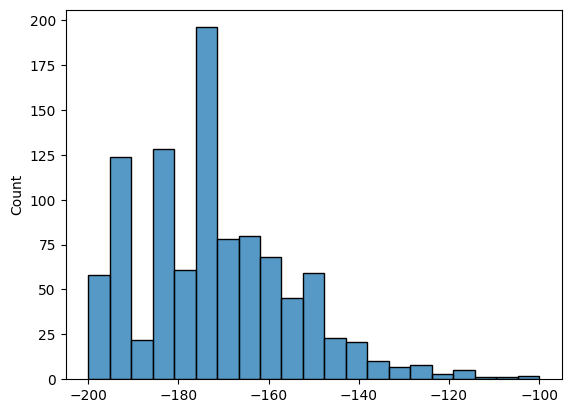

In [70]:
energy_distribution = read_file('./../data/ising_L10_T2.000_N1000_0.txt', 10, function=energy)

sns.histplot(energy_distribution)

In [ ]:
# Magnetización
def magnetization(spin):
    return np.sum(spin)


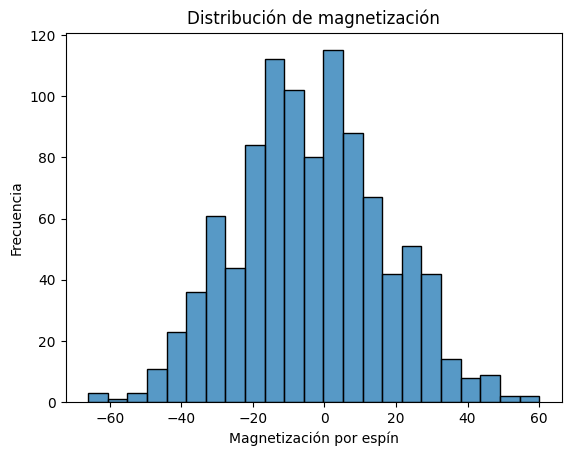

In [75]:
# Ejemplo de uso: calcular la magnetización
magnetization_distribution = read_file('./../data/ising_L10_T4.000_N1000_1.txt', 10, function=magnetization)

sns.histplot(magnetization_distribution)
plt.xlabel('Magnetización por espín')
plt.ylabel('Frecuencia')
plt.title('Distribución de magnetización')
plt.show()
